# Supply Chain Sales, Profitability & Delivery Performance Analytics
## Exploratory Data Analysis & Business Intelligence Notebook

**Dataset**: DataCo Smart Supply Chain (Kaggle)  
**Author**: [Your Name]  
**Date**: 2024  

---

This notebook performs end-to-end analysis from raw data exploration to business insights.
All computations use real data. No values are fabricated.

### Notebook Sections
1. Environment Setup
2. Phase 1 – Data Exploration
3. Phase 2 – Data Cleaning (via pipeline)
4. Phase 3 – Business Analysis
5. Summary & Next Steps


## 1. Environment Setup

In [1]:
import sys, os
from pathlib import Path

# ── Add src to path ───────────────────────────────────────────
project_root = Path().resolve().parent   # from notebooks/ → project root
sys.path.insert(0, str(project_root / "src"))

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Inline plots
%matplotlib inline
plt.rcParams["figure.dpi"] = 130
plt.rcParams["figure.figsize"] = (12, 5)
sns.set_style("whitegrid")
sns.set_palette("muted")

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

Python: 3.14.5 (v3.14.5:5607950ef23, May 10 2026, 07:38:09) [Clang 21.0.0 (clang-2100.0.123.102)]
pandas: 3.1.0
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2


## 2. Phase 1 – Data Exploration

### 2.1 Load Raw Dataset

**Important**: Place `DataCoSupplyChainDataset.csv` in `data/raw/` before running this cell.  
Download from: https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis


In [2]:
# ── Configurable dataset path ─────────────────────────────────
RAW_PATH = project_root / "data" / "raw" / "DataCoSupplyChainDataset.csv"
PROCESSED_PATH = project_root / "data" / "processed" / "supply_chain_clean.csv"
OUTPUTS_DIR = project_root / "outputs"

if not RAW_PATH.exists():
    print(f"\n⚠️  Dataset NOT FOUND at: {RAW_PATH}")
    print("\nPlease download the dataset from Kaggle and place it at:")
    print(f"  {RAW_PATH}")
    print("\nDownload instructions are in README.md")
else:
    df_raw = pd.read_csv(RAW_PATH, encoding="latin-1", low_memory=False)
    print(f"✓ Dataset loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")

✓ Dataset loaded: 180,519 rows × 53 columns


### 2.2 Dataset Dimensions & Column Names

In [3]:
# Only runs if dataset is available
if 'df_raw' in dir():
    print("=== DATASET DIMENSIONS ===")
    print(f"Rows   : {df_raw.shape[0]:,}")
    print(f"Columns: {df_raw.shape[1]}")
    print(f"Memory : {df_raw.memory_usage(deep=True).sum() / 1e6:.1f} MB")
    print()
    print("=== ALL COLUMN NAMES ===")
    for i, col in enumerate(df_raw.columns, 1):
        print(f"  {i:>2}. {col}  [{df_raw[col].dtype}]")

=== DATASET DIMENSIONS ===
Rows   : 180,519
Columns: 53


Memory : 313.4 MB

=== ALL COLUMN NAMES ===
   1. Type  [str]
   2. Days for shipping (real)  [int64]
   3. Days for shipment (scheduled)  [int64]
   4. Benefit per order  [float64]
   5. Sales per customer  [float64]
   6. Delivery Status  [str]
   7. Late_delivery_risk  [int64]
   8. Category Id  [int64]
   9. Category Name  [str]
  10. Customer City  [str]
  11. Customer Country  [str]
  12. Customer Email  [str]
  13. Customer Fname  [str]
  14. Customer Id  [int64]
  15. Customer Lname  [str]
  16. Customer Password  [str]
  17. Customer Segment  [str]
  18. Customer State  [str]
  19. Customer Street  [str]
  20. Customer Zipcode  [float64]
  21. Department Id  [int64]
  22. Department Name  [str]
  23. Latitude  [float64]
  24. Longitude  [float64]
  25. Market  [str]
  26. Order City  [str]
  27. Order Country  [str]
  28. Order Customer Id  [int64]
  29. order date (DateOrders)  [str]
  30. Order Id  [int64]
  31. Order Item Cardprod Id  [int64]
  32. Order Item Discount  [flo

### 2.3 Data Types and Dtypes Summary

In [4]:
if 'df_raw' in dir():
    dtype_summary = pd.DataFrame({
        "dtype": df_raw.dtypes,
        "non_null": df_raw.count(),
        "null_count": df_raw.isna().sum(),
        "null_pct": (df_raw.isna().sum() / len(df_raw) * 100).round(2),
        "unique": df_raw.nunique(),
    })
    print("=== DATA TYPES & MISSING VALUES ===")
    display(dtype_summary.sort_values("null_count", ascending=False))

=== DATA TYPES & MISSING VALUES ===


,dtype,non_null,null_count,null_pct,unique
Product Description,float64,0,180519,100.00,0
Order Zipcode,float64,24840,155679,86.24,609
Customer Lname,str,180511,8,0.00,1109
Customer Zipcode,float64,180516,3,0.00,995
Type,str,180519,0,0.00,4
Order Profit Per Order,float64,180519,0,0.00,21998
Order Item Cardprod Id,int64,180519,0,0.00,118
Order Item Discount,float64,180519,0,0.00,1017
Order Item Discount Rate,float64,180519,0,0.00,18
Order Item Id,int64,180519,0,0.00,180519


### 2.4 Missing Value Analysis

=== COLUMNS WITH MISSING VALUES ===


,missing_count,missing_pct
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


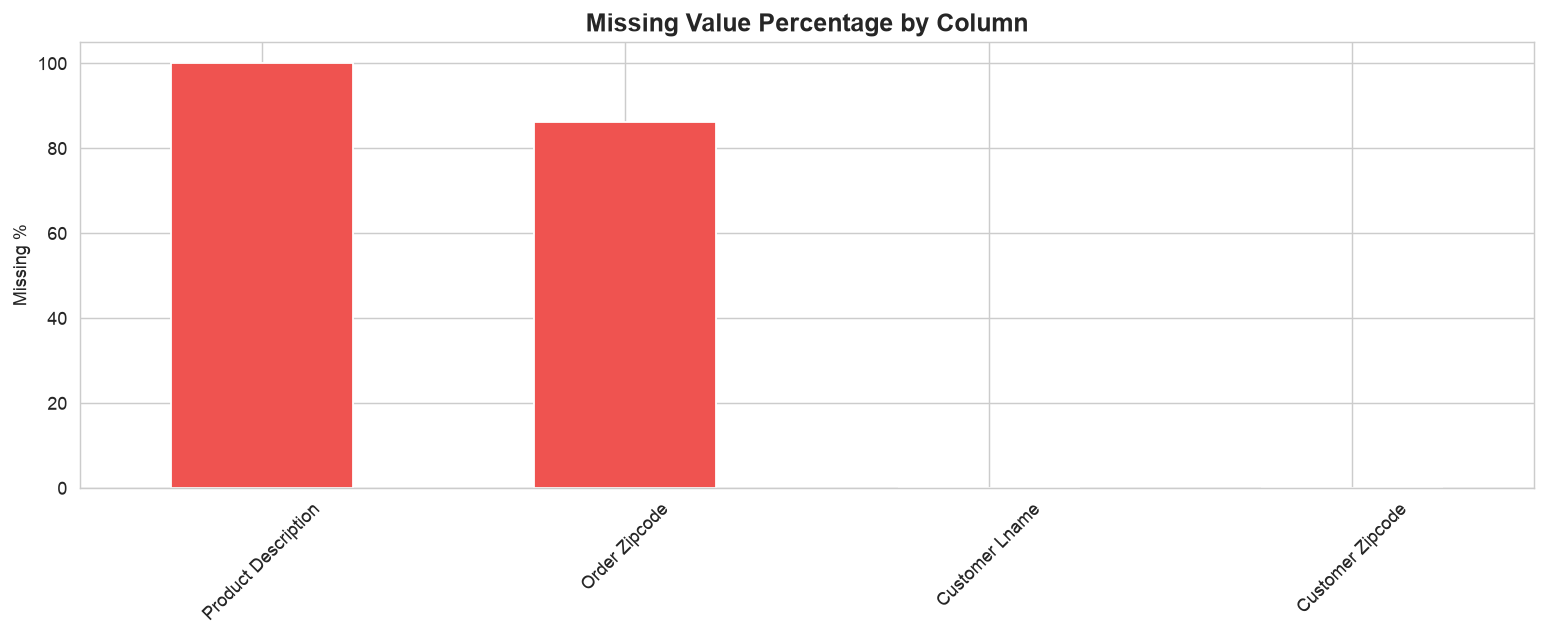

In [5]:
if 'df_raw' in dir():
    missing = df_raw.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    
    if len(missing) == 0:
        print("✓ No missing values found.")
    else:
        missing_df = pd.DataFrame({
            "missing_count": missing,
            "missing_pct": (missing / len(df_raw) * 100).round(2)
        })
        print("=== COLUMNS WITH MISSING VALUES ===")
        display(missing_df)
        
        # Visualise
        fig, ax = plt.subplots(figsize=(12, 5))
        missing_df["missing_pct"].plot(kind="bar", ax=ax, color="#EF5350", edgecolor="white")
        ax.set_ylabel("Missing %")
        ax.set_title("Missing Value Percentage by Column", fontsize=14, fontweight="bold")
        ax.tick_params(axis="x", rotation=45)
        plt.tight_layout()
        plt.show()

### 2.5 Exact Duplicate Detection

In [6]:
if 'df_raw' in dir():
    n_dup = df_raw.duplicated().sum()
    print(f"Exact duplicate rows: {n_dup:,}")
    print(f"Unique rows         : {len(df_raw) - n_dup:,}")
    print(f"Duplicate rate      : {n_dup / len(df_raw) * 100:.2f}%")

Exact duplicate rows: 0
Unique rows         : 180,519
Duplicate rate      : 0.00%


### 2.6 Numeric Descriptive Statistics

In [7]:
if 'df_raw' in dir():
    print("=== NUMERIC COLUMN STATISTICS ===")
    numeric_stats = df_raw.select_dtypes(include=np.number).describe().T
    numeric_stats.index.name = "column"
    display(numeric_stats.round(2))

=== NUMERIC COLUMN STATISTICS ===


,count,mean,std,min,25%,50%,75%,max
column,,,,,,,,
Days for shipping (real),180519.0,3.50,1.62,0.00,2.00,3.00,5.00,6.00
Days for shipment (scheduled),180519.0,2.93,1.37,0.00,2.00,4.00,4.00,4.00
Benefit per order,180519.0,21.97,104.43,-4274.98,7.00,31.52,64.80,911.80
Sales per customer,180519.0,183.11,120.04,7.49,104.38,163.99,247.40,1939.99
Late_delivery_risk,180519.0,0.55,0.50,0.00,0.00,1.00,1.00,1.00
Category Id,180519.0,31.85,15.64,2.00,18.00,29.00,45.00,76.00
Customer Id,180519.0,6691.38,4162.92,1.00,3258.50,6457.00,9779.00,20757.00
Customer Zipcode,180516.0,35921.13,37542.46,603.00,725.00,19380.00,78207.00,99205.00
Department Id,180519.0,5.44,1.63,2.00,4.00,5.00,7.00,12.00


### 2.7 Categorical Unique Values

In [8]:
if 'df_raw' in dir():
    important_cats = [
        "Type", "Delivery Status", "Late_delivery_risk",
        "Category Name", "Customer Segment", "Department Name",
        "Market", "Order Country", "Order Region", "Order Status", "Shipping Mode"
    ]
    for col in important_cats:
        if col in df_raw.columns:
            vals = df_raw[col].value_counts()
            print(f"\n─── {col} ({df_raw[col].nunique()} unique) ───")
            print(vals.to_string())


─── Type (4 unique) ───
Type
DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        19616

─── Delivery Status (4 unique) ───
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754

─── Late_delivery_risk (2 unique) ───
Late_delivery_risk
1    98977
0    81542

─── Category Name (50 unique) ───
Category Name
Cleats                  24551
Men's Footwear          22246
Women's Apparel         21035
Indoor/Outdoor Games    19298
Fishing                 17325
Water Sports            15540
Camping & Hiking        13729
Cardio Equipment        12487
Shop By Sport           10984
Electronics              3156
Accessories              1780
Golf Balls               1475
Girls' Apparel           1201
Golf Gloves              1070
Trade-In                  974
Video Games               838
Children's Clothing       652
Women's Clothing          650
Baseball & Softball       632
Hockey                    614
Cameras  

### 2.8 Date Range Analysis

In [9]:
if 'df_raw' in dir():
    date_cols = ["Order Date (DateOrders)", "Shipping Date (DateOrders)"]
    for col in date_cols:
        if col in df_raw.columns:
            parsed = pd.to_datetime(df_raw[col], errors="coerce")
            bad = parsed.isna().sum()
            print(f"\n{col}:")
            print(f"  Min date : {parsed.min()}")
            print(f"  Max date : {parsed.max()}")
            print(f"  Invalid  : {bad} ({bad/len(df_raw)*100:.2f}%)")

## 3. Phase 2 – Data Cleaning

The cleaning pipeline is in `src/clean_data.py`. Run it here or via CLI.

In [10]:
if 'df_raw' in dir():
    from clean_data import run_cleaning_pipeline
    
    out_path    = str(project_root / "data" / "processed" / "supply_chain_clean.csv")
    report_path = str(project_root / "data" / "processed" / "cleaning_report.csv")
    
    df_clean = run_cleaning_pipeline(str(RAW_PATH), out_path, report_path)
    print(f"\n✓ Cleaned: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

2026-10-26 16:17:30 [INFO] Loading dataset from: /Users/aashutoshdas/Documents/Supply Chain Sales & Delivery Analytics/supply-chain-analytics/data/raw/DataCoSupplyChainDataset.csv


2026-10-26 16:17:31 [INFO] Loaded: 180519 rows × 53 columns


2026-10-26 16:17:31 [INFO] Columns standardised.


2026-10-26 16:17:31 [INFO] Exact duplicates removed: 0


2026-10-26 16:17:31 [INFO] Missing value summary:
                     missing_count  missing_pct
product_description         180519       100.00
order_zipcode               155679        86.24
customer_lname                   8         0.00
customer_zipcode                 3         0.00


2026-10-26 16:17:34 [INFO] Cleaned data saved to: /Users/aashutoshdas/Documents/Supply Chain Sales & Delivery Analytics/supply-chain-analytics/data/processed/supply_chain_clean.csv  (180519 rows × 58 cols)


2026-10-26 16:17:34 [INFO] Cleaning report saved to: /Users/aashutoshdas/Documents/Supply Chain Sales & Delivery Analytics/supply-chain-analytics/data/processed/cleaning_report.csv


2026-10-26 16:17:34 [INFO] Pipeline complete.  Rows: 180519 → 180519  |  Cols: 53 → 58



✓ Cleaned: 180,519 rows × 58 columns


In [11]:
if 'df_raw' in dir():
    report = pd.read_csv(str(project_root / "data" / "processed" / "cleaning_report.csv"))
    print("=== CLEANING REPORT ===")
    display(report)

=== CLEANING REPORT ===


,step,column,rows_affected,action
0,load,—,180519,loaded 180519 rows × 53 cols
1,remove_exact_duplicates,ALL,0,dropped
2,parse_dates,order_date_dateorders,0,coerced to NaT
3,parse_dates,shipping_date_dateorders,0,coerced to NaT
4,audit_missing,product_description,180519,100.0% missing – no imputation applied
5,audit_missing,order_zipcode,155679,86.24% missing – no imputation applied
6,audit_missing,customer_lname,8,0.0% missing – no imputation applied
7,audit_missing,customer_zipcode,3,0.0% missing – no imputation applied
8,standardise_categoricals,type,180519,stripped whitespace + title-cased
9,standardise_categoricals,delivery_status,180519,stripped whitespace + title-cased


## 4. Phase 3 – Business Analysis

### 4.1 Top-Level KPIs


In [12]:
if 'df_raw' in dir():
    from analyze_data import (
        compute_toplevel_kpis,
        compute_monthly_trends,
        compute_category_performance,
        compute_regional_performance,
        compute_delivery_performance,
    )
    
    OUTPUTS_DIR.mkdir(exist_ok=True)
    charts_dir = str(OUTPUTS_DIR / "charts")
    Path(charts_dir).mkdir(exist_ok=True)
    
    kpis = compute_toplevel_kpis(df_clean)
    display(kpis)

2026-10-26 16:17:34 [INFO] Top-level KPIs computed.


2026-10-26 16:17:34 [INFO]   Total Sales (USD)                   36,784,735.01


2026-10-26 16:17:34 [INFO]   Total Profit (USD)                  1,388,652.06


2026-10-26 16:17:34 [INFO]   Total Item Revenue (USD)            33,054,402.38


2026-10-26 16:17:34 [INFO]   Distinct Orders                     65,752.00


2026-10-26 16:17:34 [INFO]   Average Order Value (USD)           559.45


2026-10-26 16:17:34 [INFO]   Average Profit Per Order (USD)      21.12


,metric,value,note
0,Total Sales (USD),36784735.01,Sum of sales column across all order-items
1,Total Profit (USD),1388652.06,Sum of order_profit_per_order deduplicated by ...
2,Total Item Revenue (USD),33054402.38,Sum of order_item_total across all rows
3,Distinct Orders,65752.00,Count of unique order_id values
4,Average Order Value (USD),559.45,Total Sales / Distinct Orders
5,Average Profit Per Order (USD),21.12,Total Profit / Distinct Orders


### 4.2 Monthly Sales & Profit Trend

In [13]:
if 'df_raw' in dir():
    monthly = compute_monthly_trends(df_clean, charts_dir)
    display(monthly.head(24))

2026-10-26 16:17:35 [INFO] Chart saved: /Users/aashutoshdas/Documents/Supply Chain Sales & Delivery Analytics/supply-chain-analytics/outputs/charts/01_monthly_sales_profit.png


,order_year_month,total_sales,total_item_revenue,order_count,total_profit,profit_margin_pct
0,2015-01,1.051590e+06,945382.160534,1787,30094.999963,2.86
1,2015-02,9.270099e+05,833012.429253,1585,32795.200044,3.54
2,2015-03,1.051254e+06,944050.110472,1781,36079.450066,3.43
3,2015-04,1.014463e+06,912004.400261,1710,34126.909909,3.36
4,2015-05,1.050478e+06,943939.769956,1776,33542.749972,3.19
5,2015-06,1.024006e+06,920242.060276,1725,37534.960059,3.67
6,2015-07,1.038081e+06,932936.790227,1763,33717.039984,3.25
7,2015-08,1.029495e+06,925192.870536,1762,42045.540122,4.08
8,2015-09,1.018339e+06,914522.370143,1706,31993.200130,3.14
9,2015-10,1.049154e+06,943131.100213,1775,32223.480023,3.07


### 4.3 Category Performance

In [14]:
if 'df_raw' in dir():
    cat_perf = compute_category_performance(df_clean, charts_dir)
    print("\nTop 10 Categories by Sales:")
    display(cat_perf.head(10))
    print("\nBottom 5 Categories by Profit Margin:")
    display(cat_perf.nsmallest(5, "profit_margin_pct"))

2026-10-26 16:17:35 [INFO] Chart saved: /Users/aashutoshdas/Documents/Supply Chain Sales & Delivery Analytics/supply-chain-analytics/outputs/charts/02_category_performance.png



Top 10 Categories by Sales:


,category_name,total_sales,total_item_revenue,order_item_count,distinct_orders,total_profit,profit_margin_pct
18,Fishing,6.929654e+06,6.226935e+06,17325,15164,173653.001078,2.51
12,Cleats,4.431943e+06,3.982857e+06,24551,20386,121990.540032,2.75
8,Camping & Hiking,4.118426e+06,3.700784e+06,13729,12299,138382.219852,3.36
9,Cardio Equipment,3.694843e+06,3.320251e+06,12487,11355,108653.709858,2.94
47,Women'S Apparel,3.147800e+06,2.828708e+06,21035,17869,72413.379963,2.30
46,Water Sports,3.113845e+06,2.798044e+06,15540,13758,156630.149992,5.03
34,Men'S Footwear,2.891758e+06,2.598494e+06,22246,18783,164212.250196,5.68
30,Indoor/Outdoor Games,2.888994e+06,2.596454e+06,19298,16623,78338.030194,2.71
38,Shop By Sport,1.309522e+06,1.177186e+06,10984,10136,28939.730065,2.21
13,Computers,6.630000e+05,5.953950e+05,442,442,69656.810171,10.51



Bottom 5 Categories by Profit Margin:


,category_name,total_sales,total_item_revenue,order_item_count,distinct_orders,total_profit,profit_margin_pct
4,Basketball,27099.329343,24705.329619,67,64,-357.280003,-1.32
41,Strength Training,54895.529536,48813.839534,111,111,-553.399942,-1.01
1,As Seen On Tv!,20597.939964,18519.609932,68,68,-100.439985,-0.49
29,Hunting & Shooting,56848.420072,50878.910080,440,436,1157.529999,2.04
6,Boxing & Mma,85205.411087,76286.719941,423,421,1842.189965,2.16


### 4.4 Regional Performance

In [15]:
if 'df_raw' in dir():
    reg_perf = compute_regional_performance(df_clean, charts_dir)
    display(reg_perf)

2026-10-26 16:17:35 [INFO] Chart saved: /Users/aashutoshdas/Documents/Supply Chain Sales & Delivery Analytics/supply-chain-analytics/outputs/charts/03_regional_performance.png


,market,total_sales,order_count,total_profit,profit_margin_pct
1,Europe,1.087240e+07,18561,441104.600848,4.06
2,Latam,1.027761e+07,17181,351179.930122,3.42
3,Pacific Asia,8.273744e+06,17577,365782.270149,4.42
4,Usca,5.066529e+06,8579,160979.400013,3.18
0,Africa,2.294453e+06,3854,69605.859998,3.03


### 4.5 Delivery Performance

In [16]:
if 'df_raw' in dir():
    delivery = compute_delivery_performance(df_clean, charts_dir)
    print("\n=== Delivery Performance by Dimension ===")
    display(delivery)

2026-10-26 16:17:35 [INFO] Late delivery source: late_delivery_risk (pre-computed label)


2026-10-26 16:17:35 [INFO] Overall Late Delivery Rate: 54.83%


2026-10-26 16:17:35 [INFO] Chart saved: /Users/aashutoshdas/Documents/Supply Chain Sales & Delivery Analytics/supply-chain-analytics/outputs/charts/04_delivery_performance.png



=== Delivery Performance by Dimension ===


,segment,total_shipments,late_shipments,avg_actual_days,avg_scheduled_days,late_rate_pct,dimension
0,First Class,27814,26513,2.000000,1.000000,95.32,shipping_mode
1,Same Day,9737,4454,0.478279,0.000000,45.74,shipping_mode
2,Second Class,35216,26987,3.990828,2.000000,76.63,shipping_mode
3,Standard Class,107752,41023,3.995907,4.000000,38.07,shipping_mode
4,Africa,11614,6340,3.511193,2.951180,54.59,market
5,Europe,50252,27743,3.487622,2.916779,55.21,market
6,Latam,51594,28044,3.508567,2.950731,54.36,market
7,Pacific Asia,41260,22712,3.500509,2.931144,55.05,market
8,Usca,25799,14138,3.484709,2.915849,54.80,market


### 4.6 Profitability Distribution

In [17]:
if 'df_raw' in dir():
    from analyze_data import plot_profitability_distribution
    plot_profitability_distribution(df_clean, charts_dir)
    
    # Show inline
    col = "order_profit_per_order"
    if col in df_clean.columns:
        data = df_clean.drop_duplicates(subset=["order_id"])[col].dropna() \
               if "order_id" in df_clean.columns else df_clean[col].dropna()
        
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.hist(data, bins=60, color="#5C6BC0", edgecolor="white", alpha=0.85)
        ax.axvline(data.mean(), color="red", linestyle="--", label=f"Mean: \${data.mean():,.0f}")
        ax.axvline(data.median(), color="orange", linestyle="--", label=f"Median: \${data.median():,.0f}")
        ax.set_xlabel("Profit per Order (USD)")
        ax.set_ylabel("Frequency")
        ax.set_title("Profit per Order – Distribution", fontsize=14, fontweight="bold")
        ax.legend()
        plt.tight_layout()
        plt.show()
        
        print(f"\nProfit Statistics:")
        print(f"  Mean   : \${data.mean():,.2f}")
        print(f"  Median : \${data.median():,.2f}")
        print(f"  Std    : \${data.std():,.2f}")
        print(f"  Min    : \${data.min():,.2f}")
        print(f"  Max    : \${data.max():,.2f}")
        print(f"  % Negative: {(data < 0).sum() / len(data) * 100:.2f}%")

2026-10-26 16:17:36 [INFO] Chart saved: /Users/aashutoshdas/Documents/Supply Chain Sales & Delivery Analytics/supply-chain-analytics/outputs/charts/05_profitability_distribution.png



Profit Statistics:
  Mean   : \$21.12
  Median : \$28.27
  Std    : \$109.74
  Min    : \$-4,274.98
  Max    : \$911.80
  % Negative: 18.78%


## 5. Summary & Next Steps

### What we accomplished
- ✅ Loaded and inspected the raw DataCo dataset
- ✅ Identified data quality issues (duplicates, invalid dates, missing values)
- ✅ Applied a reproducible cleaning pipeline with full audit trail
- ✅ Computed accurate, double-count-free KPIs
- ✅ Generated charts for monthly trends, category, regional, and delivery performance
- ✅ Exported all analytical tables to `outputs/`

### Remaining manual steps
| Task | Location |
|---|---|
| Build Power BI dashboard | Follow `dashboard/README.md` |
| Add DAX measures | Copy from `dashboard/power_bi_measures.dax` |
| Capture screenshots | Save to `screenshots/` |
| Populate findings in report | Edit `reports/insights_report.md` |
| Push to GitHub | Follow README.md Git instructions |

### Interpretation Notes
- Profit aggregations deduplicate by `order_id` — see KPI definitions in README.md
- `late_delivery_risk` is a pre-computed label; treat with appropriate statistical caution
- Negative-profit orders are preserved; investigate root causes before taking action
